https://www.kaggle.com/datasets/fdemoribajolin/death-classification-icu?utm_source=chatgpt.com&select=y_train_2025.csv

In [1]:
!unzip "/content/archive (3).zip"

Archive:  /content/archive (3).zip
  inflating: X_train_2025.csv        
  inflating: y_train_2025.csv        


In [2]:
import pandas as pd

x = pd.read_csv('/content/X_train_2025.csv')

y = pd.read_csv('/content/y_train_2025.csv')

x.head(3)

,recordid,SAPS-I,SOFA,Age,Gender,Height,Weight,CCU,CSRU,SICU,...,Platelets_last,TroponinI_last,TroponinT_last,WBC_last,Weight_last,pH_last,MechVentStartTime,MechVentDuration,MechVentLast8Hour,UrineOutputSum
0,137517,-1,2,56.0,0.0,NaN,79.6,0,0,0,...,444.0,NaN,NaN,7.3,79.6,NaN,NaN,NaN,NaN,NaN
1,145680,10,3,72.0,1.0,NaN,70.0,0,0,0,...,82.0,NaN,0.07,2.4,70.0,7.48,NaN,NaN,NaN,NaN
2,138649,-1,8,81.0,0.0,NaN,NaN,0,0,0,...,211.0,NaN,NaN,7.0,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
y.head(3)

,In-hospital_death
0,0
1,0
2,0


In [6]:
#we need to create a single dataframe for these features and target

df = pd.concat([x,y],axis=1)

df.head()

,recordid,SAPS-I,SOFA,Age,Gender,Height,Weight,CCU,CSRU,SICU,...,TroponinI_last,TroponinT_last,WBC_last,Weight_last,pH_last,MechVentStartTime,MechVentDuration,MechVentLast8Hour,UrineOutputSum,In-hospital_death
0,137517,-1,2,56.0,0.0,NaN,79.6,0,0,0,...,NaN,NaN,7.3,79.6,NaN,NaN,NaN,NaN,NaN,0
1,145680,10,3,72.0,1.0,NaN,70.0,0,0,0,...,NaN,0.07,2.4,70.0,7.48,NaN,NaN,NaN,NaN,0
2,138649,-1,8,81.0,0.0,NaN,NaN,0,0,0,...,NaN,NaN,7.0,NaN,NaN,NaN,NaN,NaN,NaN,0
3,149075,16,8,56.0,1.0,180.3,94.8,1,0,0,...,NaN,NaN,11.4,98.9,7.44,1128.0,470.0,0.0,4.0,0
4,141408,14,7,52.0,1.0,182.9,120.6,0,1,0,...,NaN,NaN,9.0,120.6,7.43,143.0,2580.0,1.0,16.0,0


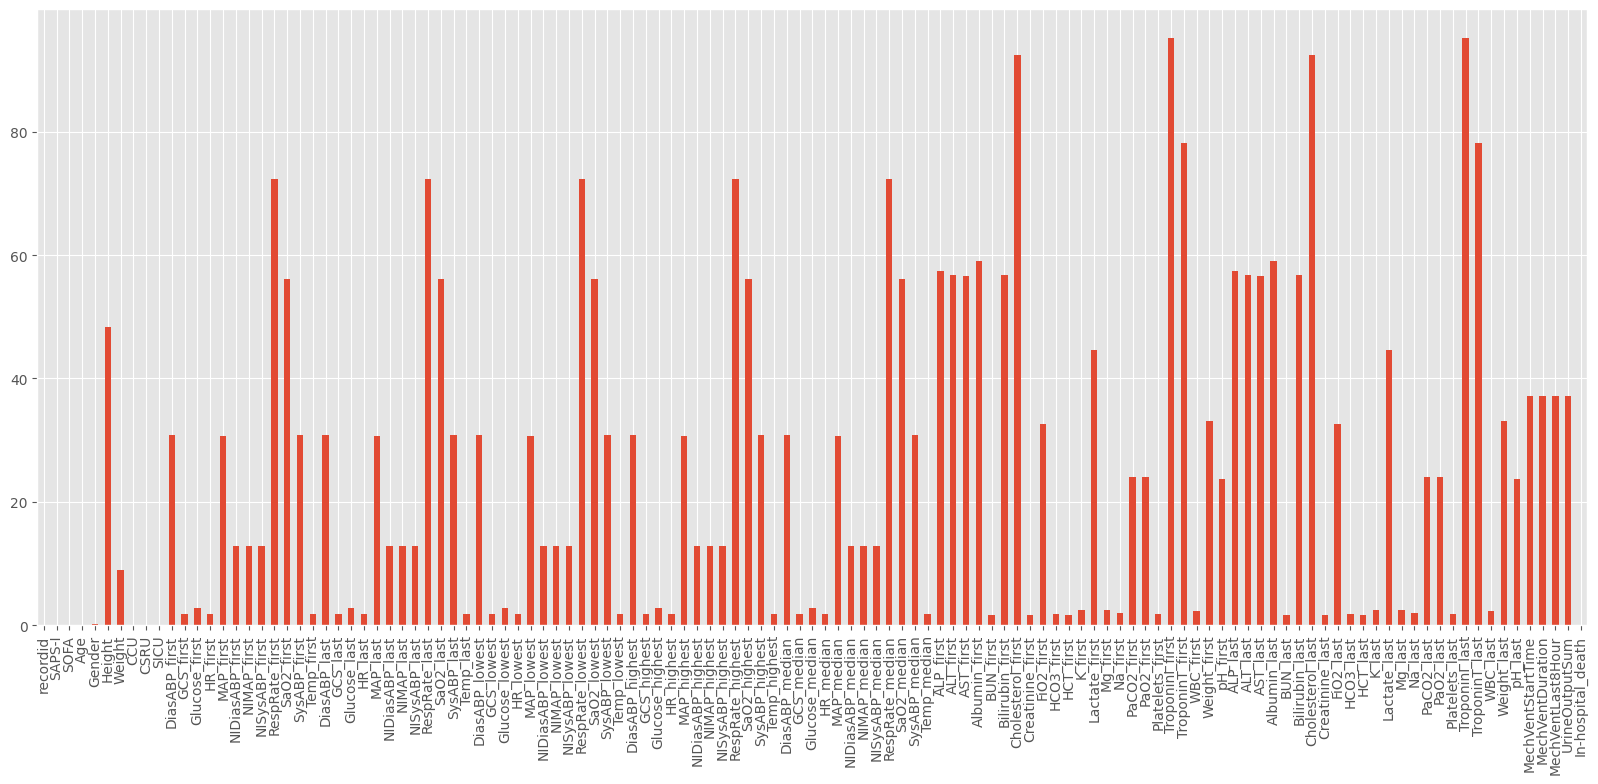

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')
plt.figure(figsize=(20,8))
(100*df.isna().sum()/len(df)).plot.bar()
plt.show()

In [14]:
missing_stats = 100*df.isna().sum()/len(df)
missing_stats[missing_stats>40]

,0
Height,48.277778
RespRate_first,72.388889
SaO2_first,56.138889
RespRate_last,72.388889
SaO2_last,56.138889
RespRate_lowest,72.388889
SaO2_lowest,56.138889
RespRate_highest,72.388889
SaO2_highest,56.138889
RespRate_median,72.388889


In [17]:
cols_to_drop = missing_stats[missing_stats>40].index.tolist()

df.drop(cols_to_drop,axis=1,inplace=True)

In [18]:
df.shape

(3600, 92)

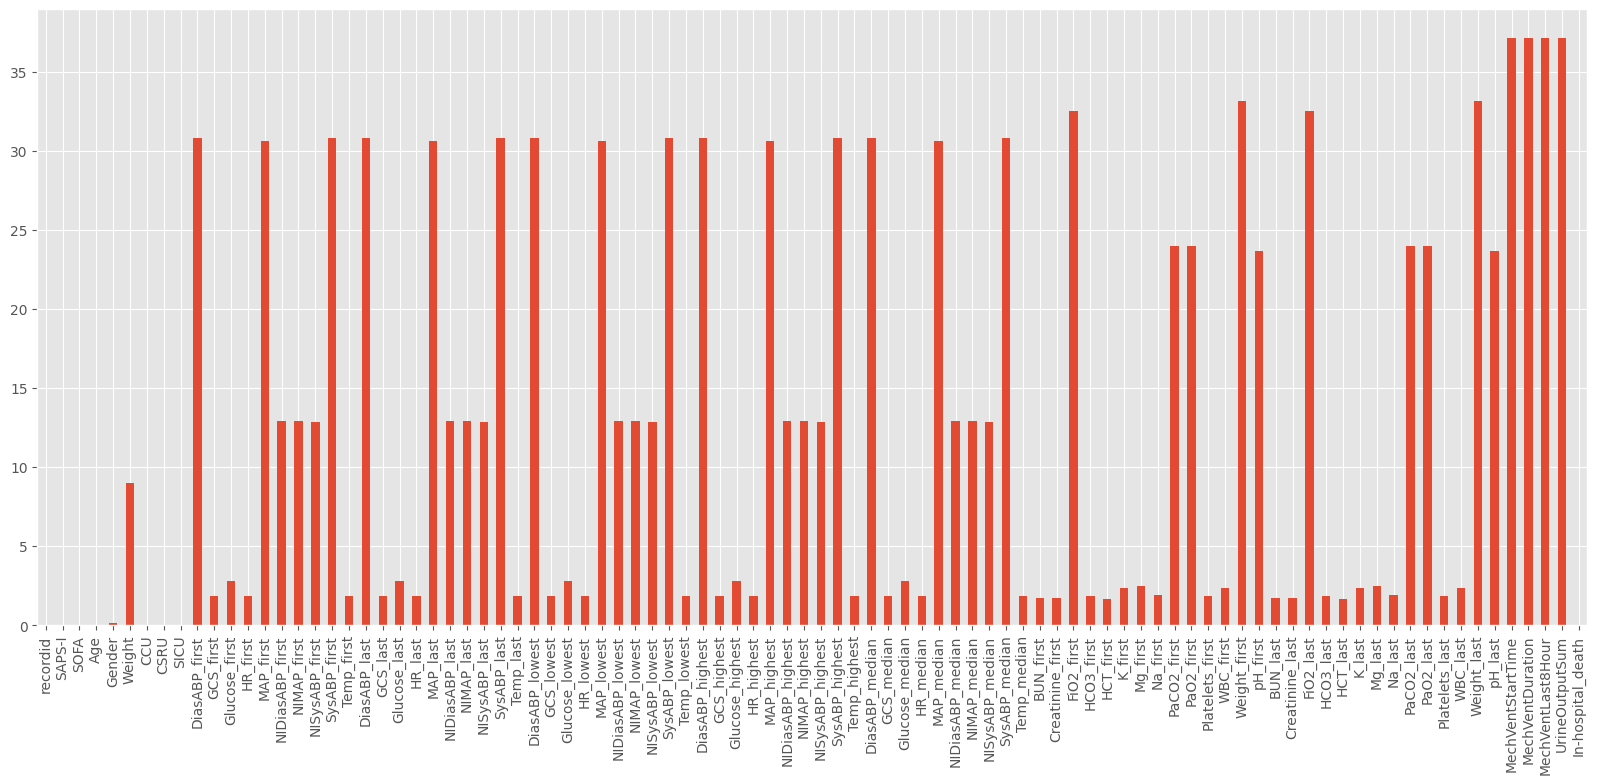

In [19]:
plt.figure(figsize=(20,8))
(100*df.isna().sum()/len(df)).plot.bar()
plt.show()

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 92 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   recordid           3600 non-null   int64  
 1   SAPS-I             3600 non-null   int64  
 2   SOFA               3600 non-null   int64  
 3   Age                3600 non-null   float64
 4   Gender             3596 non-null   float64
 5   Weight             3277 non-null   float64
 6   CCU                3600 non-null   int64  
 7   CSRU               3600 non-null   int64  
 8   SICU               3600 non-null   int64  
 9   DiasABP_first      2492 non-null   float64
 10  GCS_first          3535 non-null   float64
 11  Glucose_first      3500 non-null   float64
 12  HR_first           3535 non-null   float64
 13  MAP_first          2498 non-null   float64
 14  NIDiasABP_first    3136 non-null   float64
 15  NIMAP_first        3136 non-null   float64
 16  NISysABP_first     3138 

In [21]:
num_cols = []
cat_cols = []

for col in df.columns[:-1]:
  if len(df[col].unique()) in [2,3,4,5,6,7,8,9,10]:
    cat_cols.append(col)
  else:
    num_cols.append(col)


In [23]:
len(num_cols)

86

In [24]:
len(cat_cols)

5

In [28]:
cat_cols

['Gender', 'CCU', 'CSRU', 'SICU', 'MechVentLast8Hour']

In [ ]:
for col in num_cols:
  if df[col].skew()>0.5 or df[col].skew()<-0.5:
    df[col].fillna(df[col].median(),inplace=True)
  elif df[col].skew()<0.5 or df[col].skew()>-0.5:
    df[col].fillna(df[col].mean(),inplace=True)



In [27]:
df[num_cols].isna().sum().sum()

np.int64(0)

In [32]:
df['Gender'].mode().values[0]

np.float64(1.0)

In [ ]:
for col in cat_cols:
  df[col].fillna(df[col].mode().values[0],inplace=True)



In [34]:
df[cat_cols].isna().sum()

,0
Gender,0
CCU,0
CSRU,0
SICU,0
MechVentLast8Hour,0


In [35]:
#we have fixed the missingness problem
df.head()

,recordid,SAPS-I,SOFA,Age,Gender,Weight,CCU,CSRU,SICU,DiasABP_first,...,PaO2_last,Platelets_last,WBC_last,Weight_last,pH_last,MechVentStartTime,MechVentDuration,MechVentLast8Hour,UrineOutputSum,In-hospital_death
0,137517,-1,2,56.0,0.0,79.6,0,0,0,62.552568,...,105.0,444.0,7.3,79.6,7.41,118.0,2281.5,1.0,12.120141,0
1,145680,10,3,72.0,1.0,70.0,0,0,0,62.552568,...,95.0,82.0,2.4,70.0,7.48,118.0,2281.5,1.0,12.120141,0
2,138649,-1,8,81.0,0.0,79.0,0,0,0,62.552568,...,105.0,211.0,7.0,82.0,7.41,118.0,2281.5,1.0,12.120141,0
3,149075,16,8,56.0,1.0,94.8,1,0,0,55.000000,...,78.0,204.0,11.4,98.9,7.44,1128.0,470.0,0.0,4.000000,0
4,141408,14,7,52.0,1.0,120.6,0,1,0,80.000000,...,83.0,352.0,9.0,120.6,7.43,143.0,2580.0,1.0,16.000000,0


In [36]:
df.isna().sum().sum()

np.int64(0)

In [37]:
df.drop(['recordid'],axis=1,inplace=True)

In [38]:
df.shape

(3600, 91)

In [40]:
df.duplicated().sum()

np.int64(0)

In [39]:
df.to_csv('cleaned_data_I.csv',index=False)

#Dataset Overview

Rows: 3,600 patients

Columns: 91 features

Target Variable: In-hospital_death

Missing Values: None (already cleaned)

#Problem Type: Binary Classification

Domain: ICU / Critical Care Healthcare Prediction


The dataset is clearly designed for predicting patient mortality during hospital stay using ICU monitoring, vitals, lab results, ventilation information, and severity scores.

#Target Variable
In-hospital_death

0 → Patient survived

1 → Patient died during hospitalization

#Class Distribution

Survived: 3097

Died: 503

This means:

#Mortality rate ≈ 13.97%

Dataset is moderately imbalanced

In [43]:
num_cols.remove('recordid')

In [44]:
# Dictionary to store outlier counts
outlier_counts = {}

# IQR Method
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_counts[col] = outliers.shape[0]

# Convert to DataFrame
outlier_df = pd.DataFrame({
    'Feature': outlier_counts.keys(),
    'Outlier_Count': outlier_counts.values()
})

# Sort values
outlier_df = outlier_df.sort_values(by='Outlier_Count', ascending=False)

outlier_df

,Feature,Outlier_Count
84,UrineOutputSum,757
28,MAP_lowest,645
82,MechVentStartTime,525
66,Weight_first,487
32,SysABP_lowest,475
...,...,...
5,GCS_first,0
15,GCS_last,0
25,GCS_lowest,0
45,GCS_median,0


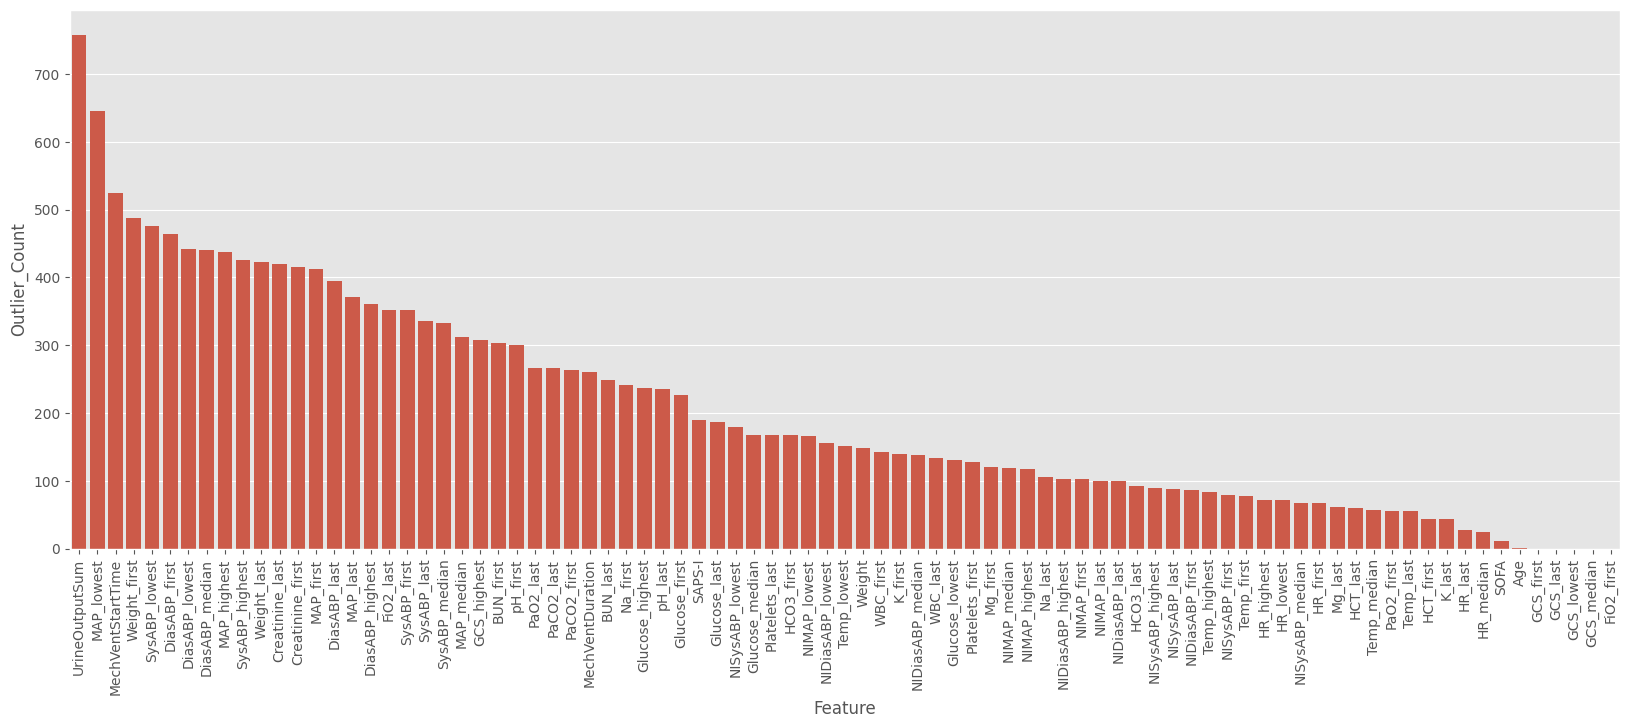

In [47]:

plt.figure(figsize=(20,7))
sns.barplot(data=outlier_df,x = 'Feature',y = 'Outlier_Count')
plt.xticks(rotation=90)
plt.show()

In [49]:
# IQR Capping
import numpy as np
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap values
    df[col] = np.where(df[col] < lower_bound,
                              lower_bound,
                              df[col])

    df[col] = np.where(df[col] > upper_bound,
                              upper_bound,
                              df[col])


#we fixed the outliers by capping them

#reason :

For this dataset, you should mostly cap the outliers instead of dropping rows.

#Why?

This is a healthcare ICU dataset, and many “outliers” are actually clinically important extreme patient conditions, not data errors.

#Examples:

Very high heart rate → critically ill patient

Very low blood pressure → shock

High glucose → diabetic emergency

Abnormal oxygen → respiratory failure


If you remove them, you may accidentally remove the sickest patients — exactly the cases important for predicting mortality.

In [51]:
df.columns

Index(['SAPS-I', 'SOFA', 'Age', 'Gender', 'Weight', 'CCU', 'CSRU', 'SICU',
       'DiasABP_first', 'GCS_first', 'Glucose_first', 'HR_first', 'MAP_first',
       'NIDiasABP_first', 'NIMAP_first', 'NISysABP_first', 'SysABP_first',
       'Temp_first', 'DiasABP_last', 'GCS_last', 'Glucose_last', 'HR_last',
       'MAP_last', 'NIDiasABP_last', 'NIMAP_last', 'NISysABP_last',
       'SysABP_last', 'Temp_last', 'DiasABP_lowest', 'GCS_lowest',
       'Glucose_lowest', 'HR_lowest', 'MAP_lowest', 'NIDiasABP_lowest',
       'NIMAP_lowest', 'NISysABP_lowest', 'SysABP_lowest', 'Temp_lowest',
       'DiasABP_highest', 'GCS_highest', 'Glucose_highest', 'HR_highest',
       'MAP_highest', 'NIDiasABP_highest', 'NIMAP_highest', 'NISysABP_highest',
       'SysABP_highest', 'Temp_highest', 'DiasABP_median', 'GCS_median',
       'Glucose_median', 'HR_median', 'MAP_median', 'NIDiasABP_median',
       'NIMAP_median', 'NISysABP_median', 'SysABP_median', 'Temp_median',
       'BUN_first', 'Creatinine_first', '

In [50]:
df.head()

,SAPS-I,SOFA,Age,Gender,Weight,CCU,CSRU,SICU,DiasABP_first,GCS_first,...,PaO2_last,Platelets_last,WBC_last,Weight_last,pH_last,MechVentStartTime,MechVentDuration,MechVentLast8Hour,UrineOutputSum,In-hospital_death
0,0.5,2.0,56.0,0.0,79.6,0,0,0,62.552568,15.0,...,105.0,394.375,7.3,79.60,7.41,118.0,2281.5,1.0,12.120141,0
1,10.0,3.0,72.0,1.0,70.0,0,0,0,62.552568,15.0,...,95.0,82.000,2.4,70.00,7.48,118.0,2281.5,1.0,12.120141,0
2,0.5,8.0,81.0,0.0,79.0,0,0,0,62.552568,6.0,...,105.0,211.000,7.0,82.00,7.41,118.0,2281.5,1.0,12.120141,0
3,16.0,8.0,56.0,1.0,94.8,1,0,0,55.000000,15.0,...,78.0,204.000,11.4,98.90,7.44,264.0,570.0,0.0,6.500000,0
4,14.0,7.0,52.0,1.0,120.6,0,1,0,79.500000,10.0,...,83.0,352.000,9.0,110.35,7.43,143.0,2580.0,1.0,16.000000,0


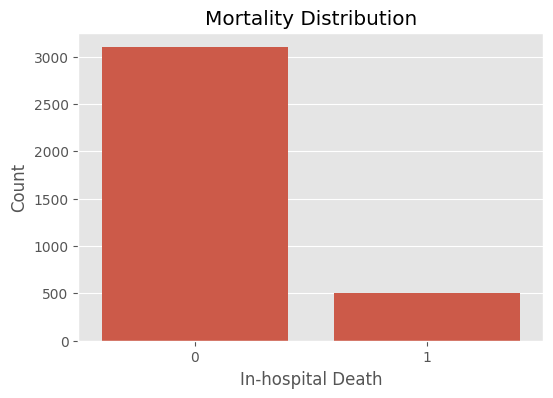

In-hospital_death
0    86.027778
1    13.972222
Name: proportion, dtype: float64


In [52]:
# -----------------------------
# TARGET VARIABLE ANALYSIS
# -----------------------------

plt.figure(figsize=(6,4))
sns.countplot(x='In-hospital_death', data=df)
plt.title("Mortality Distribution")
plt.xlabel("In-hospital Death")
plt.ylabel("Count")
plt.show()

print(df['In-hospital_death'].value_counts(normalize=True) * 100)

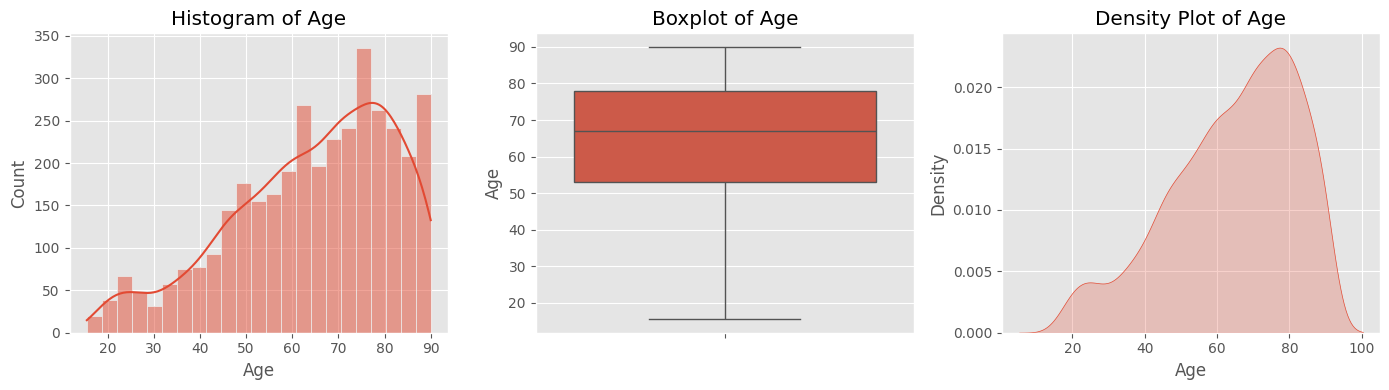

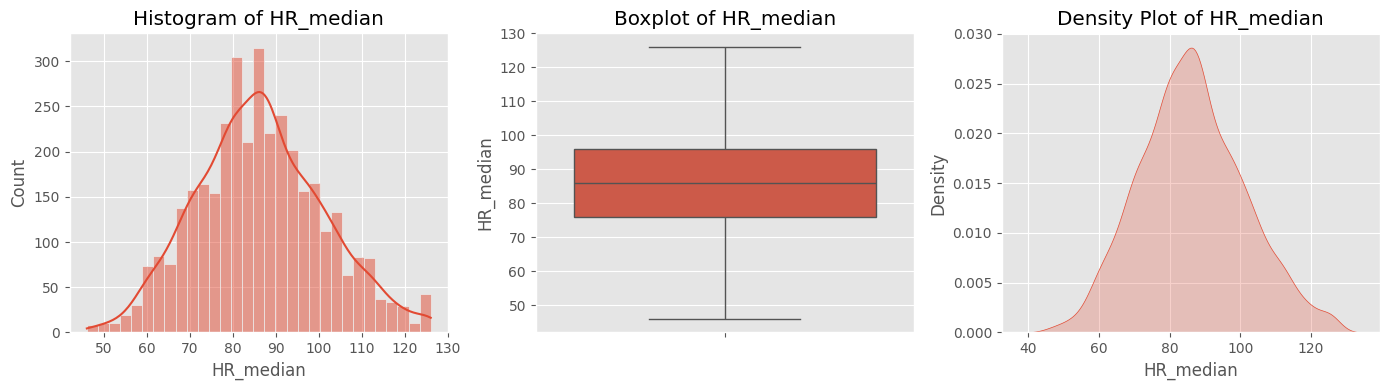

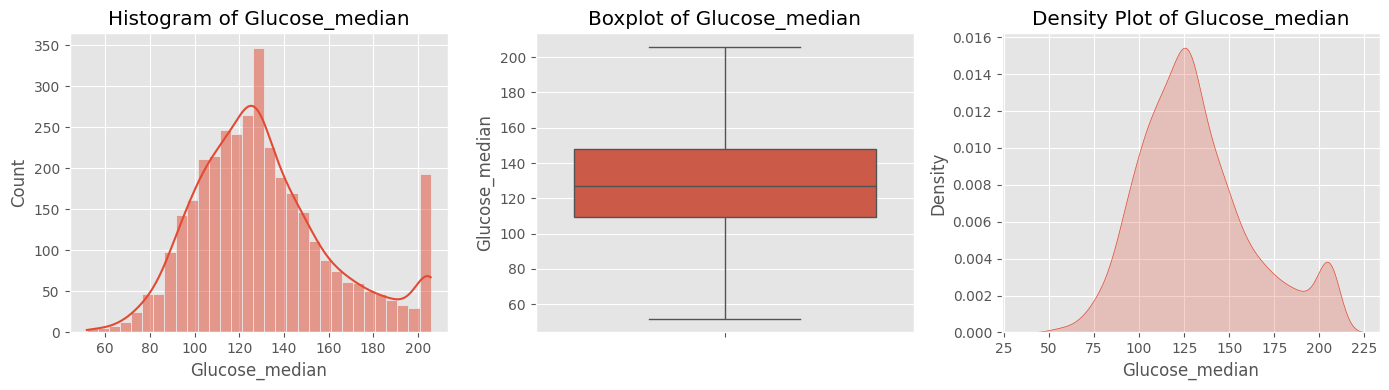

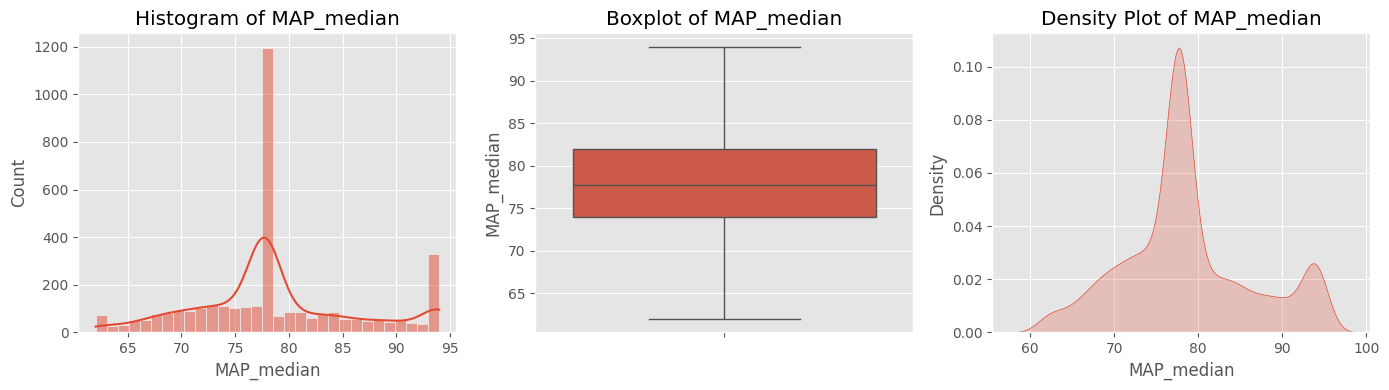

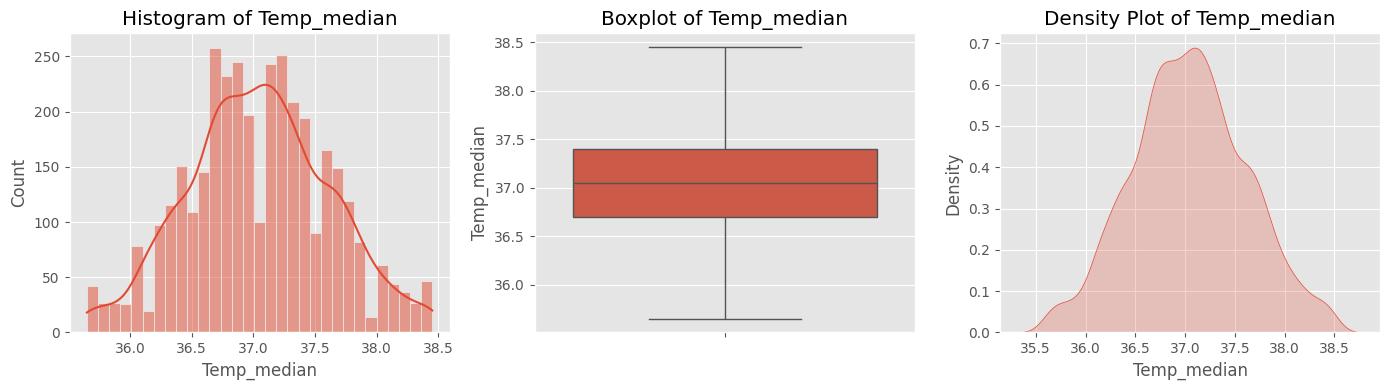

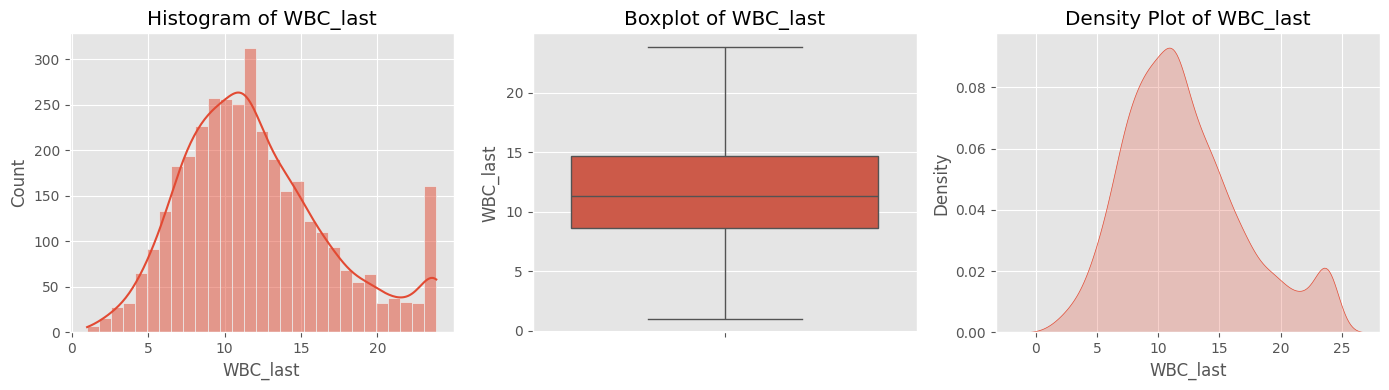

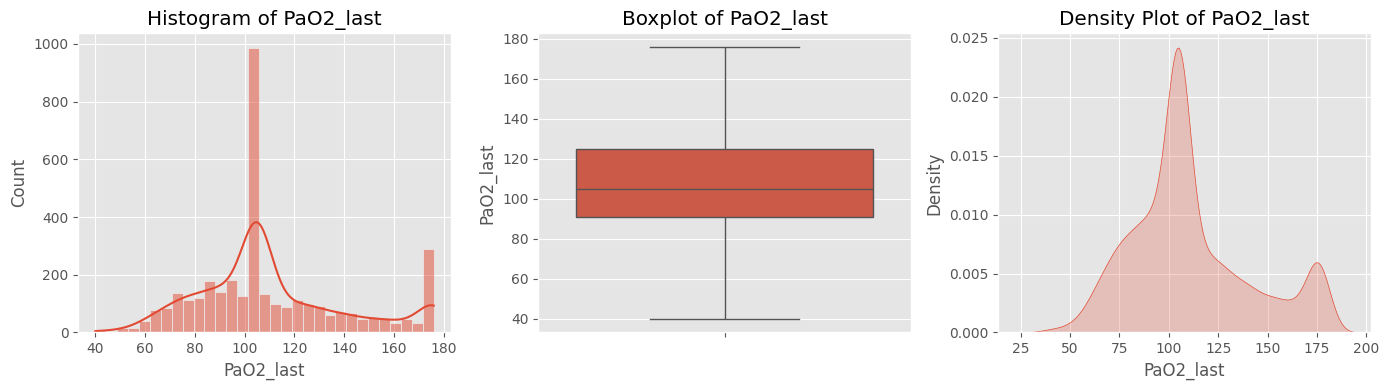

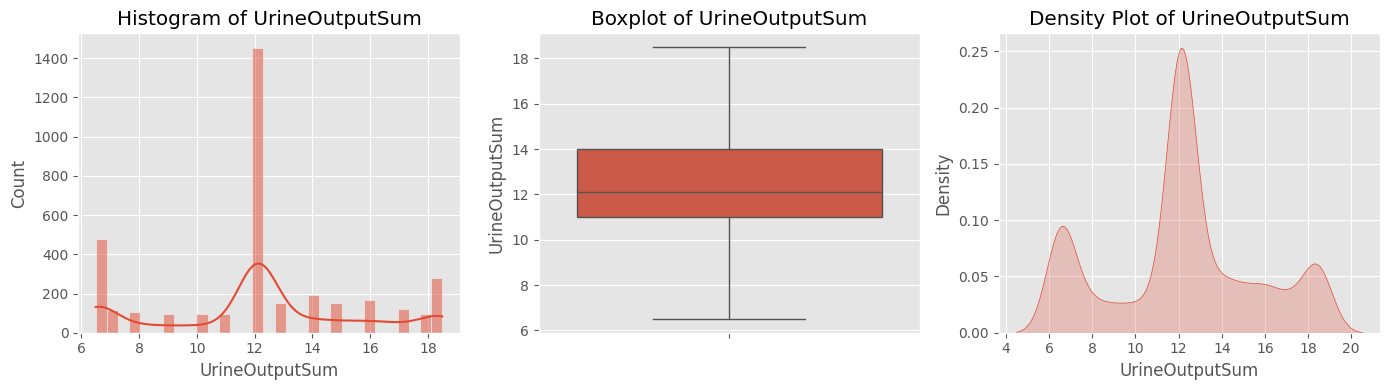

In [53]:
# -----------------------------
# UNIVARIATE ANALYSIS
# -----------------------------

important_features = [
    'Age',
    'HR_median',
    'Glucose_median',
    'MAP_median',
    'Temp_median',
    'WBC_last',
    'PaO2_last',
    'UrineOutputSum'
]

for col in important_features:

    plt.figure(figsize=(14,4))

    # Histogram
    plt.subplot(1,3,1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Histogram of {col}')

    # Boxplot
    plt.subplot(1,3,2)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

    # Density Plot
    plt.subplot(1,3,3)
    sns.kdeplot(df[col], fill=True)
    plt.title(f'Density Plot of {col}')

    plt.tight_layout()
    plt.show()


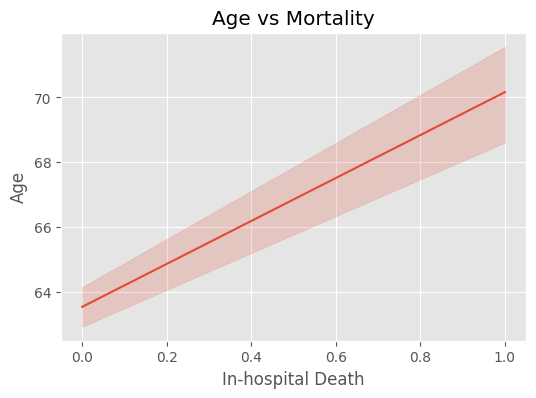

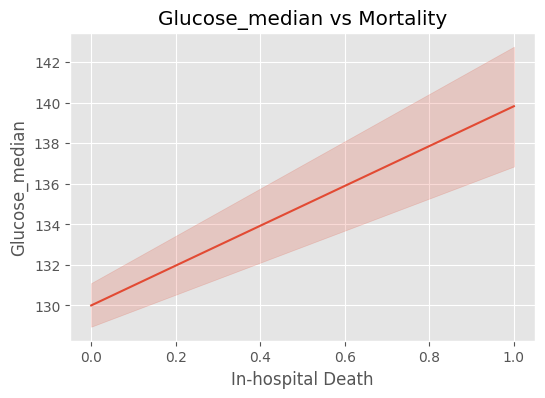

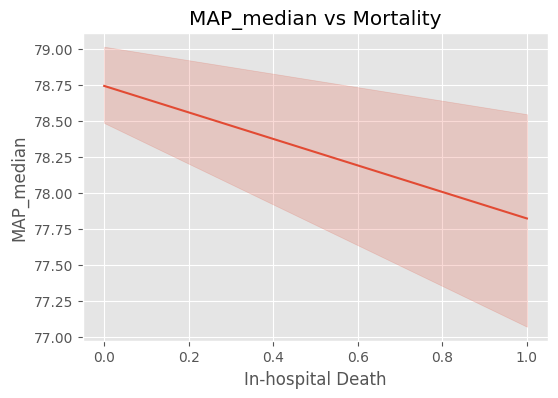

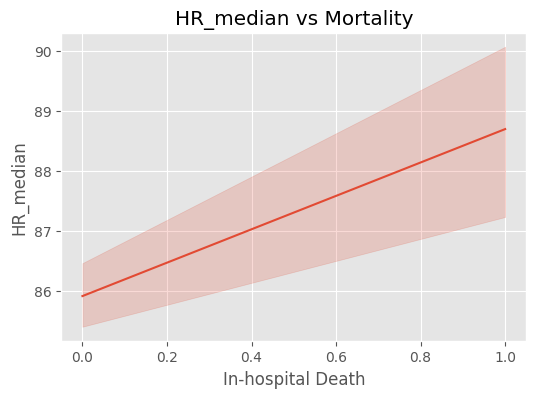

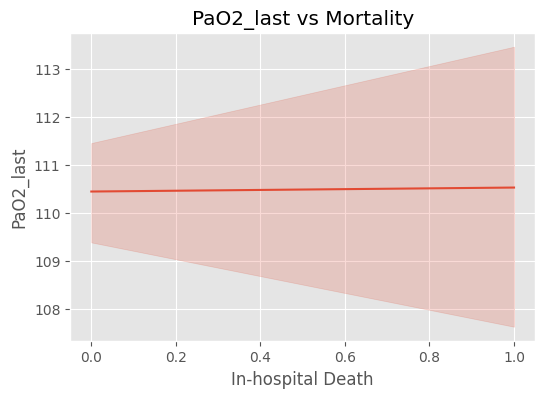

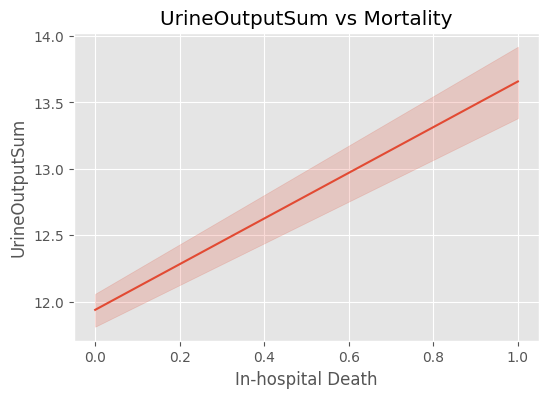

In [56]:
# -----------------------------
# BIVARIATE ANALYSIS
# Mortality Relationships
# -----------------------------

mortality_features = [
    'Age',
    'Glucose_median',
    'MAP_median',
    'HR_median',
    'PaO2_last',
    'UrineOutputSum'
]

for col in mortality_features:

    plt.figure(figsize=(6,4))
    sns.lineplot(x='In-hospital_death', y=col, data=df)

    plt.title(f'{col} vs Mortality')
    plt.xlabel('In-hospital Death')
    plt.ylabel(col)

    plt.show()


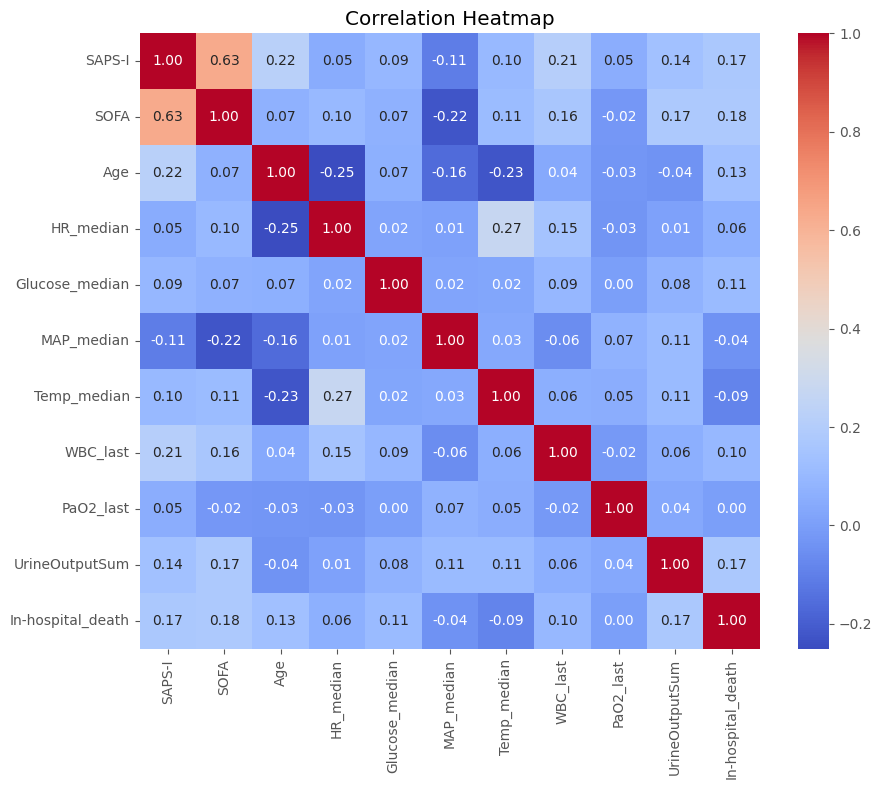

In [57]:
# -----------------------------
# CORRELATION HEATMAP
# -----------------------------

corr_features = [
    'SAPS-I',
    'SOFA',
    'Age',
    'HR_median',
    'Glucose_median',
    'MAP_median',
    'Temp_median',
    'WBC_last',
    'PaO2_last',
    'UrineOutputSum',
    'In-hospital_death'
]

corr_matrix = df[corr_features].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix,
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()

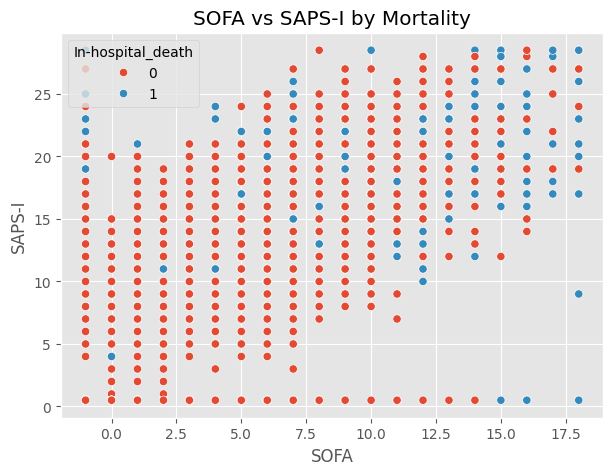

In [58]:
# -----------------------------
# MULTIVARIATE ANALYSIS
# ICU RISK TREND VISUALIZATION
# -----------------------------

plt.figure(figsize=(7,5))

sns.scatterplot(
    x='SOFA',
    y='SAPS-I',
    hue='In-hospital_death',
    data=df
)

plt.title("SOFA vs SAPS-I by Mortality")
plt.show()


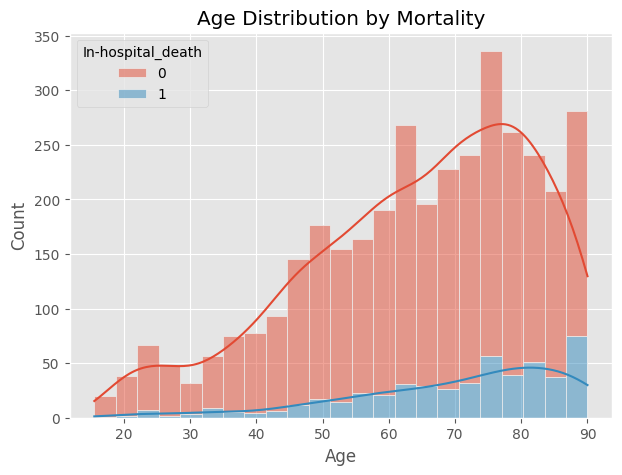

In [59]:
# -----------------------------
# AGE RELATED MORTALITY
# -----------------------------

plt.figure(figsize=(7,5))

sns.histplot(
    data=df,
    x='Age',
    hue='In-hospital_death',
    kde=True,
    multiple='stack'
)

plt.title("Age Distribution by Mortality")
plt.show()

In [60]:
df.groupby(['In-hospital_death'])['Age'].mean()

,Age
In-hospital_death,
0,63.53681
1,70.16501


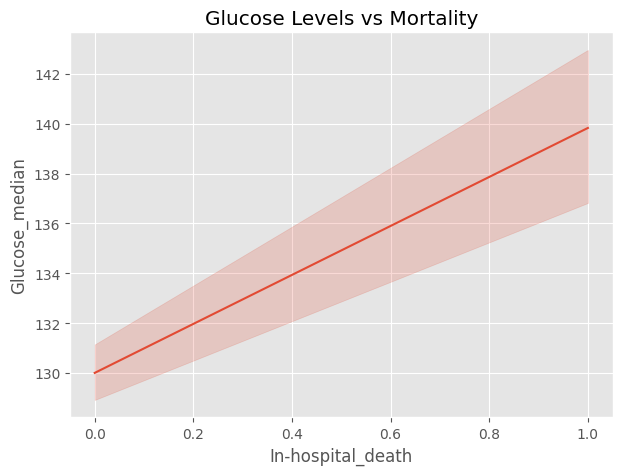

In [63]:
# -----------------------------
# GLUCOSE VS MORTALITY
# -----------------------------

plt.figure(figsize=(7,5))

sns.lineplot(
    x='In-hospital_death',
    y='Glucose_median',
    data=df
)

plt.title("Glucose Levels vs Mortality")
plt.show()

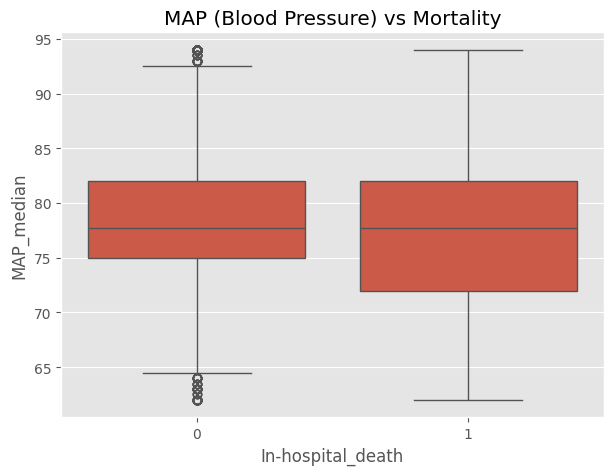

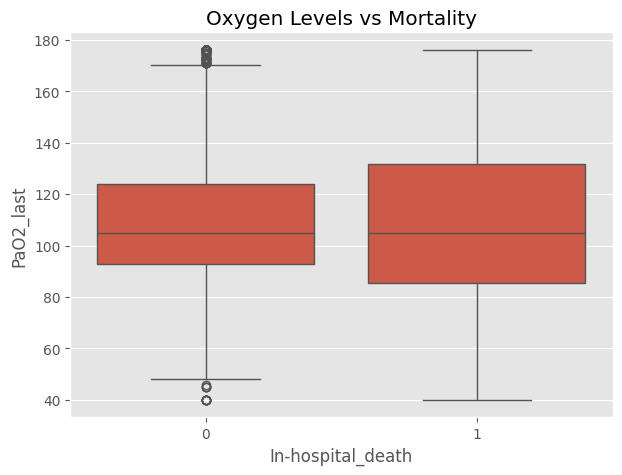

In [64]:
# -----------------------------
# BLOOD PRESSURE VS MORTALITY
# -----------------------------

plt.figure(figsize=(7,5))

sns.boxplot(
    x='In-hospital_death',
    y='MAP_median',
    data=df
)

plt.title("MAP (Blood Pressure) vs Mortality")
plt.show()


# -----------------------------
# OXYGEN SATURATION ANALYSIS
# -----------------------------

plt.figure(figsize=(7,5))

sns.boxplot(
    x='In-hospital_death',
    y='PaO2_last',
    data=df
)

plt.title("Oxygen Levels vs Mortality")
plt.show()



In [69]:
# -----------------------------
# ICU UNIT MORTALITY ANALYSIS
# -----------------------------


icu_cols = ['CCU', 'CSRU', 'SICU']

for col in icu_cols:
  print(df.groupby(col)['In-hospital_death'].mean())
  print('---------'*100)

CCU
0    0.139625
1    0.140316
Name: In-hospital_death, dtype: float64
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
CSRU
0    0.167785
1    0.0

In [70]:
num_cols

['SAPS-I',
 'SOFA',
 'Age',
 'Weight',
 'DiasABP_first',
 'GCS_first',
 'Glucose_first',
 'HR_first',
 'MAP_first',
 'NIDiasABP_first',
 'NIMAP_first',
 'NISysABP_first',
 'SysABP_first',
 'Temp_first',
 'DiasABP_last',
 'GCS_last',
 'Glucose_last',
 'HR_last',
 'MAP_last',
 'NIDiasABP_last',
 'NIMAP_last',
 'NISysABP_last',
 'SysABP_last',
 'Temp_last',
 'DiasABP_lowest',
 'GCS_lowest',
 'Glucose_lowest',
 'HR_lowest',
 'MAP_lowest',
 'NIDiasABP_lowest',
 'NIMAP_lowest',
 'NISysABP_lowest',
 'SysABP_lowest',
 'Temp_lowest',
 'DiasABP_highest',
 'GCS_highest',
 'Glucose_highest',
 'HR_highest',
 'MAP_highest',
 'NIDiasABP_highest',
 'NIMAP_highest',
 'NISysABP_highest',
 'SysABP_highest',
 'Temp_highest',
 'DiasABP_median',
 'GCS_median',
 'Glucose_median',
 'HR_median',
 'MAP_median',
 'NIDiasABP_median',
 'NIMAP_median',
 'NISysABP_median',
 'SysABP_median',
 'Temp_median',
 'BUN_first',
 'Creatinine_first',
 'FiO2_first',
 'HCO3_first',
 'HCT_first',
 'K_first',
 'Mg_first',
 'Na_fi

In [71]:
cat_cols

['Gender', 'CCU', 'CSRU', 'SICU', 'MechVentLast8Hour']

In [72]:

from scipy.stats import pearsonr, spearmanr
from scipy.stats import chi2_contingency
from scipy.stats import f_oneway
from scipy.stats import shapiro



# -----------------------------
# COLUMN GROUPS
# -----------------------------

num_cols = [
    'SAPS-I','SOFA','Age','Weight','DiasABP_first','GCS_first',
    'Glucose_first','HR_first','MAP_first','NIDiasABP_first',
    'NIMAP_first','NISysABP_first','SysABP_first','Temp_first',
    'DiasABP_last','GCS_last','Glucose_last','HR_last','MAP_last',
    'NIDiasABP_last','NIMAP_last','NISysABP_last','SysABP_last',
    'Temp_last','DiasABP_lowest','GCS_lowest','Glucose_lowest',
    'HR_lowest','MAP_lowest','NIDiasABP_lowest','NIMAP_lowest',
    'NISysABP_lowest','SysABP_lowest','Temp_lowest',
    'DiasABP_highest','GCS_highest','Glucose_highest',
    'HR_highest','MAP_highest','NIDiasABP_highest',
    'NIMAP_highest','NISysABP_highest','SysABP_highest',
    'Temp_highest','DiasABP_median','GCS_median',
    'Glucose_median','HR_median','MAP_median',
    'NIDiasABP_median','NIMAP_median','NISysABP_median',
    'SysABP_median','Temp_median','BUN_first',
    'Creatinine_first','FiO2_first','HCO3_first',
    'HCT_first','K_first','Mg_first','Na_first',
    'PaCO2_first','PaO2_first','Platelets_first',
    'WBC_first','Weight_first','pH_first',
    'BUN_last','Creatinine_last','FiO2_last',
    'HCO3_last','HCT_last','K_last','Mg_last',
    'Na_last','PaCO2_last','PaO2_last',
    'Platelets_last','WBC_last','Weight_last',
    'pH_last','MechVentStartTime',
    'MechVentDuration','UrineOutputSum'
]

cat_cols = ['Gender', 'CCU', 'CSRU', 'SICU', 'MechVentLast8Hour']

target = 'In-hospital_death'


# =========================================================
# 1. PEARSON CORRELATION TEST
# Numerical vs Numerical(Binary Target)
# Assumes linear relationship
# =========================================================

print("\n==============================")
print("PEARSON CORRELATION TEST")
print("==============================\n")

for col in num_cols:

    corr, p_value = pearsonr(df[col], df[target])

    result = "Significant" if p_value < 0.05 else "Not Significant"

    print(f"{col}")
    print(f"Pearson Correlation: {corr:.4f}")
    print(f"P-value: {p_value:.5f}")
    print(f"Result: {result}")
    print("-" * 50)


# =========================================================
# 2. SPEARMAN CORRELATION TEST
# Numerical vs Numerical(Binary Target)
# Handles nonlinear monotonic relationships
# =========================================================

print("\n==============================")
print("SPEARMAN CORRELATION TEST")
print("==============================\n")

for col in num_cols:

    corr, p_value = spearmanr(df[col], df[target])

    result = "Significant" if p_value < 0.05 else "Not Significant"

    print(f"{col}")
    print(f"Spearman Correlation: {corr:.4f}")
    print(f"P-value: {p_value:.5f}")
    print(f"Result: {result}")
    print("-" * 50)


# =========================================================
# 3. CHI-SQUARE TEST
# Categorical vs Categorical(Binary Target)
# =========================================================

print("\n==============================")
print("CHI-SQUARE TEST")
print("==============================\n")

for col in cat_cols:

    contingency_table = pd.crosstab(df[col], df[target])

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    result = "Significant" if p_value < 0.05 else "Not Significant"

    print(f"{col}")
    print(f"Chi2 Statistic: {chi2:.4f}")
    print(f"P-value: {p_value:.5f}")
    print(f"Result: {result}")
    print("-" * 50)


# =========================================================
# 4. ANOVA TEST
# Compare mean differences between mortality groups
# Numerical Feature vs Binary Target Groups
# =========================================================

print("\n==============================")
print("ANOVA TEST")
print("==============================\n")

for col in num_cols:

    survived = df[df[target] == 0][col]
    deceased = df[df[target] == 1][col]

    f_stat, p_value = f_oneway(survived, deceased)

    result = "Significant" if p_value < 0.05 else "Not Significant"

    print(f"{col}")
    print(f"F-Statistic: {f_stat:.4f}")
    print(f"P-value: {p_value:.5f}")
    print(f"Result: {result}")
    print("-" * 50)


# =========================================================
# 5. SHAPIRO-WILK NORMALITY TEST
# ONLY for Numerical Columns
# Uses sample because Shapiro is expensive on large data
# =========================================================

print("\n==============================")
print("SHAPIRO-WILK NORMALITY TEST")
print("==============================\n")

# Random sample
sample_df = df[num_cols].sample(500, random_state=42)

for col in num_cols:

    stat, p_value = shapiro(sample_df[col])

    result = (
        "Normally Distributed"
        if p_value > 0.05
        else "Not Normally Distributed"
    )

    print(f"{col}")
    print(f"Statistic: {stat:.4f}")
    print(f"P-value: {p_value:.5f}")
    print(f"Result: {result}")
    print("-" * 50)


PEARSON CORRELATION TEST

SAPS-I
Pearson Correlation: 0.1737
P-value: 0.00000
Result: Significant
--------------------------------------------------
SOFA
Pearson Correlation: 0.1754
P-value: 0.00000
Result: Significant
--------------------------------------------------
Age
Pearson Correlation: 0.1304
P-value: 0.00000
Result: Significant
--------------------------------------------------
Weight
Pearson Correlation: -0.0790
P-value: 0.00000
Result: Significant
--------------------------------------------------
DiasABP_first
Pearson Correlation: -0.0480
P-value: 0.00398
Result: Significant
--------------------------------------------------
GCS_first
Pearson Correlation: -0.0109
P-value: 0.51334
Result: Not Significant
--------------------------------------------------
Glucose_first
Pearson Correlation: 0.0725
P-value: 0.00001
Result: Significant
--------------------------------------------------
HR_first
Pearson Correlation: 0.0796
P-value: 0.00000
Result: Significant
-------------------

| Variable         | Pearson | Pearson Sig.    | Spearman | Spearman Sig.   | ANOVA F-Stat | ANOVA Sig.      | Shapiro Normality |
| ---------------- | ------- | --------------- | -------- | --------------- | ------------ | --------------- | ----------------- |
| SAPS-I           | 0.1737  | Significant     | 0.1800   | Significant     | 111.9247     | Significant     | Not Normal        |
| SOFA             | 0.1754  | Significant     | 0.1529   | Significant     | 114.1977     | Significant     | Not Normal        |
| Age              | 0.1304  | Significant     | 0.1386   | Significant     | 62.2008      | Significant     | Not Normal        |
| Weight           | -0.0790 | Significant     | -0.0839  | Significant     | 22.6039      | Significant     | Not Normal        |
| GCS_last         | -0.3464 | Significant     | -0.3254  | Significant     | 490.6106     | Significant     | Not Normal        |
| GCS_median       | -0.2742 | Significant     | -0.2577  | Significant     | 292.6191     | Significant     | Not Normal        |
| GCS_highest      | -0.2337 | Significant     | -0.2445  | Significant     | 207.8984     | Significant     | Not Normal        |
| Glucose_highest  | 0.1372  | Significant     | 0.1330   | Significant     | 69.0331      | Significant     | Not Normal        |
| Glucose_median   | 0.1083  | Significant     | 0.1075   | Significant     | 42.6633      | Significant     | Not Normal        |
| Glucose_last     | 0.1076  | Significant     | 0.1021   | Significant     | 42.1667      | Significant     | Not Normal        |
| HR_highest       | 0.1225  | Significant     | 0.1117   | Significant     | 54.8357      | Significant     | Not Normal        |
| HR_median        | 0.0648  | Significant     | 0.0579   | Significant     | 15.1750      | Significant     | Not Normal        |
| HR_last          | 0.0766  | Significant     | 0.0698   | Significant     | 21.2475      | Significant     | Not Normal        |
| MAP_lowest       | -0.0927 | Significant     | -0.0922  | Significant     | 31.1823      | Significant     | Not Normal        |
| MAP_median       | -0.0417 | Significant     | -0.0413  | Significant     | 6.2673       | Significant     | Not Normal        |
| Temp_lowest      | -0.0926 | Significant     | -0.0894  | Significant     | 31.1272      | Significant     | Not Normal        |
| Temp_median      | -0.0859 | Significant     | -0.0841  | Significant     | 26.7517      | Significant     | Not Normal        |
| BUN_first        | 0.2129  | Significant     | 0.1977   | Significant     | 170.7910     | Significant     | Not Normal        |
| BUN_last         | 0.2433  | Significant     | 0.2182   | Significant     | 226.4549     | Significant     | Not Normal        |
| Creatinine_first | 0.1561  | Significant     | 0.1407   | Significant     | 89.8090      | Significant     | Not Normal        |
| Creatinine_last  | 0.1620  | Significant     | 0.1353   | Significant     | 96.9591      | Significant     | Not Normal        |
| HCO3_first       | -0.0768 | Significant     | -0.0753  | Significant     | 21.3743      | Significant     | Not Normal        |
| HCO3_last        | -0.1810 | Significant     | -0.1755  | Significant     | 121.8116     | Significant     | Not Normal        |
| PaCO2_first      | -0.0696 | Significant     | -0.0813  | Significant     | 17.4964      | Significant     | Not Normal        |
| PaCO2_last       | -0.0990 | Significant     | -0.1067  | Significant     | 35.6188      | Significant     | Not Normal        |
| PaO2_first       | -0.0990 | Significant     | -0.1175  | Significant     | 35.6055      | Significant     | Not Normal        |
| WBC_first        | 0.0578  | Significant     | 0.0504   | Significant     | 12.0502      | Significant     | Not Normal        |
| WBC_last         | 0.0983  | Significant     | 0.0772   | Significant     | 35.1325      | Significant     | Not Normal        |
| pH_first         | -0.0444 | Significant     | -0.0348  | Significant     | 7.0933       | Significant     | Not Normal        |
| pH_last          | -0.0708 | Significant     | -0.0519  | Significant     | 18.1511      | Significant     | Not Normal        |
| MechVentDuration | 0.1672  | Significant     | 0.1790   | Significant     | 103.5295     | Significant     | Not Normal        |
| UrineOutputSum   | 0.1712  | Significant     | 0.1710   | Significant     | 108.6247     | Significant     | Not Normal        |
| HR_first         | 0.0796  | Significant     | 0.0801   | Significant     | 22.9147      | Significant     | Normal            |
| HCT_first        | -0.0173 | Not Significant | -0.0197  | Not Significant | 1.0819       | Not Significant | Normal            |


#CHI SQUARE FOR CATEGORICAL COLUMNS

| Categorical Variable | Chi-Square Statistic | P-value | Significance    |
| -------------------- | -------------------- | ------- | --------------- |
| Gender               | 1.1362               | 0.28646 | Not Significant |
| CCU                  | 0.0000               | 1.00000 | Not Significant |
| CSRU                 | 85.7426              | < 0.001 | Significant     |
| SICU                 | 1.0700               | 0.30094 | Not Significant |
| MechVentLast8Hour    | 97.0814              | < 0.001 | Significant     |


#SIGNIFICANT FEATURES

| Feature Category                | Significant Features                                                                                                                                                                                                                                                                                  | Clinical Interpretation                                                                         |
| ------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------------- |
| Severity Scores                 | SAPS-I, SOFA                                                                                                                                                                                                                                                                                          | Higher severity and organ failure scores were strongly associated with increased mortality risk |
| Demographics                    | Age, Weight                                                                                                                                                                                                                                                                                           | Older age and lower weight were associated with worse ICU outcomes                              |
| Neurological Features           | GCS_last, GCS_median, GCS_highest, GCS_lowest                                                                                                                                                                                                                                                         | Neurological deterioration showed the strongest association with mortality                      |
| Blood Pressure Features         | DiasABP_first, DiasABP_last, DiasABP_lowest, DiasABP_median, MAP_last, MAP_lowest, MAP_median, NIDiasABP_last, NIDiasABP_lowest, NIDiasABP_median, NIMAP_last, NIMAP_lowest, NIMAP_median, NISysABP_first, NISysABP_last, NISysABP_lowest, NISysABP_median, SysABP_last, SysABP_lowest, SysABP_median | Lower blood pressure and circulatory instability were linked with mortality                     |
| Heart Rate Features             | HR_first, HR_last, HR_highest, HR_median                                                                                                                                                                                                                                                              | Elevated heart rate patterns were associated with critically ill patients                       |
| Temperature Features            | Temp_last, Temp_lowest, Temp_median                                                                                                                                                                                                                                                                   | Abnormal body temperature regulation was associated with mortality                              |
| Glucose Features                | Glucose_first, Glucose_last, Glucose_highest, Glucose_median                                                                                                                                                                                                                                          | Hyperglycemia and glucose instability increased mortality risk                                  |
| Kidney Function Features        | BUN_first, BUN_last, Creatinine_first, Creatinine_last, UrineOutputSum                                                                                                                                                                                                                                | Renal dysfunction strongly contributed to poor outcomes                                         |
| Respiratory Features            | PaCO2_first, PaCO2_last, PaO2_first, FiO2_last, MechVentDuration, MechVentLast8Hour                                                                                                                                                                                                                   | Respiratory instability and prolonged ventilation were major mortality indicators               |
| Metabolic / Acid-Base Features  | HCO3_first, HCO3_last, pH_first, pH_last                                                                                                                                                                                                                                                              | Acid-base imbalance and metabolic dysfunction were associated with mortality                    |
| Electrolyte Features            | Mg_first, Mg_last, Na_last                                                                                                                                                                                                                                                                            | Electrolyte disturbances contributed to physiological instability                               |
| Infection / Hematology Features | WBC_first, WBC_last                                                                                                                                                                                                                                                                                   | Elevated infection and inflammatory markers were linked with mortality                          |
| Weight Monitoring Features      | Weight_first, Weight_last                                                                                                                                                                                                                                                                             | Weight-related physiological changes reflected disease progression                              |
| ICU / Unit Features             | CSRU                                                                                                                                                                                                                                                                                                  | CSRU admission showed significant association with mortality outcomes                           |


In [73]:
df.head()

,SAPS-I,SOFA,Age,Gender,Weight,CCU,CSRU,SICU,DiasABP_first,GCS_first,...,PaO2_last,Platelets_last,WBC_last,Weight_last,pH_last,MechVentStartTime,MechVentDuration,MechVentLast8Hour,UrineOutputSum,In-hospital_death
0,0.5,2.0,56.0,0.0,79.6,0,0,0,62.552568,15.0,...,105.0,394.375,7.3,79.60,7.41,118.0,2281.5,1.0,12.120141,0
1,10.0,3.0,72.0,1.0,70.0,0,0,0,62.552568,15.0,...,95.0,82.000,2.4,70.00,7.48,118.0,2281.5,1.0,12.120141,0
2,0.5,8.0,81.0,0.0,79.0,0,0,0,62.552568,6.0,...,105.0,211.000,7.0,82.00,7.41,118.0,2281.5,1.0,12.120141,0
3,16.0,8.0,56.0,1.0,94.8,1,0,0,55.000000,15.0,...,78.0,204.000,11.4,98.90,7.44,264.0,570.0,0.0,6.500000,0
4,14.0,7.0,52.0,1.0,120.6,0,1,0,79.500000,10.0,...,83.0,352.000,9.0,110.35,7.43,143.0,2580.0,1.0,16.000000,0
